In [2]:
# Step 1: Import necessary libraries
import pandas as pd
import numpy as np


In [3]:
# Step 2: Load the dataset
df = pd.read_csv("D:\\Data science\\codes\\files\\bangalore house price.csv")
print(df.shape)
# Step 3: Define features and target
X = df.drop(columns=['price'])  # All columns except the target
y = df['price']

(7120, 108)




*   A target column "price"

*   107 independent variables (e.g., bath, total_sqft_int, location dummy variables)




In [4]:

# Step 4: Split into train and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)


In [ ]:
# Step 5: Standardize and apply Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

lr_pipeline = make_pipeline(StandardScaler(), LinearRegression())
lr_pipeline.fit(X_train, y_train)


,steps,"[('standardscaler', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None


We create a pipeline to standardize features and apply Linear Regression.

*   StandardScaler() makes all features have mean 0 and variance 1.
*   Linear regression is then trained on scaled data.



In [6]:
# Evaluate Linear Regression
y_train_pred = lr_pipeline.predict(X_train)
y_test_pred = lr_pipeline.predict(X_test)

from sklearn.metrics import r2_score
print("Linear Regression:")
print("Train R²:", r2_score(y_train, y_train_pred))
print("Test R² :", r2_score(y_test, y_test_pred))

Linear Regression:
Train R²: 0.8675079893347636
Test R² : 0.8138673589364601


In [7]:
# Step 6: Apply ShuffleSplit Cross-Validation
from sklearn.model_selection import ShuffleSplit, cross_val_score

shuffle_split = ShuffleSplit(n_splits=100, test_size=0.2)
cv_scores = cross_val_score(lr_pipeline, X, y, cv=shuffle_split, scoring='r2')
#cv_scores = cross_val_score(lr_pipeline, X, y, cv=5, scoring='r2', n_jobs=-1
#print("Cross-Validation R² Scores:", cv_scores)
print("Average CV R²:", np.round(cv_scores.mean(),2))


Average CV R²: 0.85


We apply ShuffleSplit, a kind of cross-validation that:

Randomly shuffles the data

*   Performs 5 different train-test splits
*   Reports R² scores on each split
*   This helps verify the model's consistency and generalization.


In [8]:
# Step 7: Apply LassoCV to find optimal alpha
from sklearn.linear_model import Lasso, LassoCV

lasso_cv_pipeline = make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=10000,alphas = None))
lasso_cv_pipeline.fit(X_train, y_train)

c:\Users\abhir\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1641: FutureWarning: 'alphas=None' is deprecated and will be removed in 1.9, at which point the default value will be set to 100. Set 'alphas=100' to silence this warning.
  warnings.warn(


,steps,"[('standardscaler', ...), ('lassocv', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,eps,0.001
,n_alphas,'deprecated'
,alphas,None
,fit_intercept,True


1. scikit-learn automatically sets alphas=None, which then triggers this logic inside LassoCV:

  “If alphas is None, use 100 values on a log scale between alpha_max and alpha_max * eps, where eps=0.001

2. max_iter=100, it defaults to 100 iterations (in scikit-learn). But if the loss hasn’t converged in 100 steps, you’ll get warning, hence better to keep highest number

In [9]:

print("All alphas tried by LassoCV:", lasso_cv_pipeline.named_steps['lassocv'].alphas_)


All alphas tried by LassoCV: [93.14458229 86.86694919 81.01240755 75.55244242 70.46046067 65.71166144
 61.28291539 57.152652   53.30075454 49.70846207 46.3582781  43.23388531
 40.32006614 37.60262863 35.06833731 32.70484874 30.5006514  28.44500958
 26.52791113 24.74001871 23.07262425 21.5176066  20.06739193 18.71491688
 17.45359411 16.27728029 15.18024607 14.15714829 13.20300388 12.31316561
 11.48329946 10.70936351  9.98758825  9.31445823  8.68669492  8.10124075
  7.55524424  7.04604607  6.57116614  6.12829154  5.7152652   5.33007545
  4.97084621  4.63582781  4.32338853  4.03200661  3.76026286  3.50683373
  3.27048487  3.05006514  2.84450096  2.65279111  2.47400187  2.30726242
  2.15176066  2.00673919  1.87149169  1.74535941  1.62772803  1.51802461
  1.41571483  1.32030039  1.23131656  1.14832995  1.07093635  0.99875883
  0.93144582  0.86866949  0.81012408  0.75552442  0.70460461  0.65711661
  0.61282915  0.57152652  0.53300755  0.49708462  0.46358278  0.43233885
  0.40320066  0.376026

In [10]:
# Extract best alpha
best_alpha = lasso_cv_pipeline.named_steps['lassocv'].alpha_
print("Best alpha from LassoCV:", best_alpha)

Best alpha from LassoCV: 0.1518024607346196


In [11]:
# Evaluate performance with best alpha
y_train_lasso = lasso_cv_pipeline.predict(X_train)
y_test_lasso = lasso_cv_pipeline.predict(X_test)
print("LassoCV Train R²:", np.round(r2_score(y_train, y_train_lasso)*100,2))
print("LassoCV Test R² :", np.round(r2_score(y_test, y_test_lasso)*100,2))

LassoCV Train R²: 86.73
LassoCV Test R² : 81.21


In [12]:
# Step 8: Plot alpha vs CV error
mse_path = lasso_cv_pipeline.named_steps['lassocv'].mse_path_.mean(axis=1)
alphas_tested = lasso_cv_pipeline.named_steps['lassocv'].alphas_
alphas_tested

array([93.14458229, 86.86694919, 81.01240755, 75.55244242, 70.46046067,
       65.71166144, 61.28291539, 57.152652  , 53.30075454, 49.70846207,
       46.3582781 , 43.23388531, 40.32006614, 37.60262863, 35.06833731,
       32.70484874, 30.5006514 , 28.44500958, 26.52791113, 24.74001871,
       23.07262425, 21.5176066 , 20.06739193, 18.71491688, 17.45359411,
       16.27728029, 15.18024607, 14.15714829, 13.20300388, 12.31316561,
       11.48329946, 10.70936351,  9.98758825,  9.31445823,  8.68669492,
        8.10124075,  7.55524424,  7.04604607,  6.57116614,  6.12829154,
        5.7152652 ,  5.33007545,  4.97084621,  4.63582781,  4.32338853,
        4.03200661,  3.76026286,  3.50683373,  3.27048487,  3.05006514,
        2.84450096,  2.65279111,  2.47400187,  2.30726242,  2.15176066,
        2.00673919,  1.87149169,  1.74535941,  1.62772803,  1.51802461,
        1.41571483,  1.32030039,  1.23131656,  1.14832995,  1.07093635,
        0.99875883,  0.93144582,  0.86866949,  0.81012408,  0.75

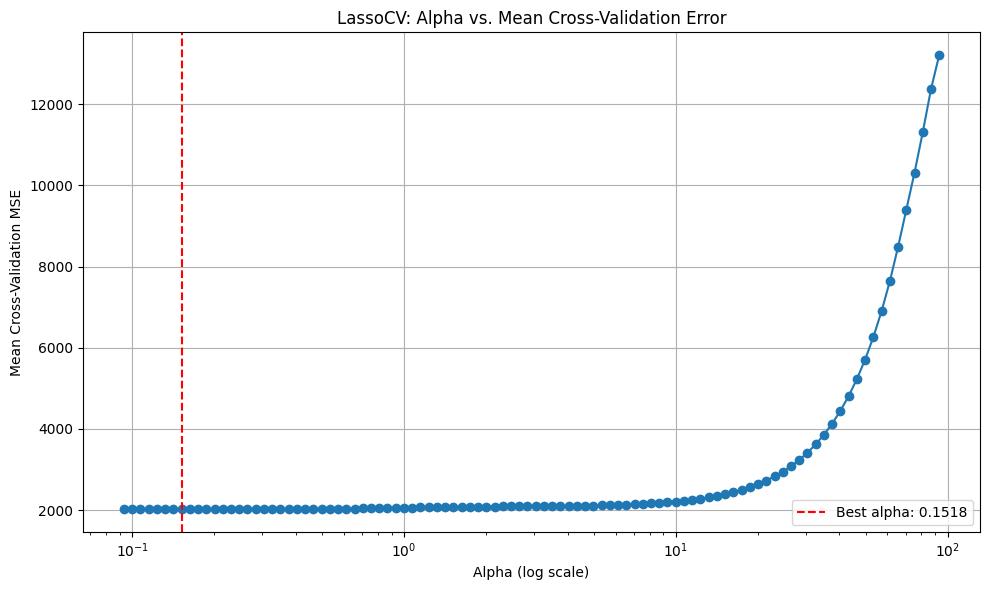

In [13]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(alphas_tested, mse_path, marker='o')
plt.axvline(best_alpha, color='red', linestyle='--', label=f'Best alpha: {best_alpha:.4f}')
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('Mean Cross-Validation MSE')
plt.title('LassoCV: Alpha vs. Mean Cross-Validation Error')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



*   We plot the mean cross-validation error (MSE) against different alphas.

*   A red line shows the best alpha (0.1758 in this case).
* Helps visually confirm the best tradeoff between bias and variance.






In [14]:
# Step 9: Feature selection — count zeroed coefficients
lasso_model = lasso_cv_pipeline.named_steps['lassocv']
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lasso_model.coef_
})
zeroed_features = coef_df[coef_df['Coefficient'] == 0]
print("Number of features removed by LassoCV:", len(zeroed_features))


Number of features removed by LassoCV: 14






*   We examine which coefficients were set to zero by Lasso.
*   These features are considered not useful
*   Lasso at α = 0.1758 removed 14 features (i.e., retained 93)




In [15]:
# Step 10: Test with higher alpha to simplify model
for alpha_val in [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1,1.1,1.2]:
    lasso_custom = make_pipeline(StandardScaler(), Lasso(alpha=alpha_val, max_iter=10000))
    lasso_custom.fit(X_train, y_train)

    y_test_pred = lasso_custom.predict(X_test)
    r2_test = r2_score(y_test, y_test_pred)
    non_zero_count = sum(lasso_custom.named_steps['lasso'].coef_ != 0)

    print(f"\nAlpha: {alpha_val}")
    print(f"Test R²: {r2_test:.4f}")
    print(f"Retained Features: {non_zero_count}")


Alpha: 0.1
Test R²: 0.8127
Retained Features: 97

Alpha: 0.2
Test R²: 0.8114
Retained Features: 91

Alpha: 0.3
Test R²: 0.8101
Retained Features: 79

Alpha: 0.4
Test R²: 0.8086
Retained Features: 74

Alpha: 0.5
Test R²: 0.8072
Retained Features: 67

Alpha: 0.6
Test R²: 0.8058
Retained Features: 59

Alpha: 0.7
Test R²: 0.8044
Retained Features: 54

Alpha: 0.8
Test R²: 0.8030
Retained Features: 45

Alpha: 0.9
Test R²: 0.8016
Retained Features: 43

Alpha: 1
Test R²: 0.8002
Retained Features: 36

Alpha: 1.1
Test R²: 0.7990
Retained Features: 34

Alpha: 1.2
Test R²: 0.7978
Retained Features: 26


In [16]:
# Step 11: Final model with alpha = 0.9 (recommended)
final_alpha = 0.9
final_lasso = make_pipeline(StandardScaler(), Lasso(alpha=final_alpha, max_iter=10000))
final_lasso.fit(X_train, y_train)

final_coef = final_lasso.named_steps['lasso'].coef_
selected_features = X.columns[final_coef != 0]
print("\nFinal Selected Features (alpha = 0.9):", len(selected_features))


Final Selected Features (alpha = 0.9): 43


In [ ]:
# Final evaluation
y_train_final = final_lasso.predict(X_train)
y_test_final = final_lasso.predict(X_test)

print("Final Lasso Train R²:", np.round(r2_score(y_train, y_train_lasso)*100,2))
print("Final Lasso Test R² :", np.round(r2_score(y_test, y_test_lasso)*100,2))

Final Lasso Train R²: 86.73
Final Lasso Test R² : 81.21


In [18]:
# prompt: print the feature names which are finalized from above after using alpha as 0.9

selected_features

Index(['total_sqft_int', 'bhk', 'price_per_sqft',
       'area_typeSuper built-up  Area', 'area_typePlot  Area',
       'location_Whitefield', 'location_Sarjapur  Road',
       'location_Raja Rajeshwari Nagar', 'location_Hennur Road',
       'location_Uttarahalli', 'location_Thanisandra',
       'location_Electronic City Phase II', 'location_Hebbal',
       'location_7th Phase JP Nagar', 'location_KR Puram', 'location_Sarjapur',
       'location_Rajaji Nagar', 'location_Begur Road', 'location_Harlur',
       'location_Jakkur', 'location_Chandapura', 'location_Kundalahalli',
       'location_Koramangala', 'location_Hegde Nagar', 'location_Channasandra',
       'location_Bisuvanahalli', 'location_Indira Nagar', 'location_Kengeri',
       'location_Old Airport Road', 'location_Bommasandra',
       'location_Thigalarapalya', 'location_Ambedkar Nagar',
       'location_Yelahanka New Town', 'location_Frazer Town',
       'location_Attibele', 'location_Anekal', 'location_Ananth Nagar',
      